# ACTG-175
---
An AIDS clinical trial group dataset.
Aiming to do Causal Inference, as well as other analyses here

### Loading data

In [1]:
red_theme <- "#ea9999"

In [2]:
install.packages("speff2trial")


Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



In [3]:
library(tidyverse) # still getting familiar
library(speff2trial)
library(survival)
library(grf)

── Attaching core tidyverse packages ─────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.2
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ───────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: leaps

Loading required package: survival



In [4]:
data("ACTG175")

In [5]:
df <- ACTG175

In [6]:
dim(ACTG175)

[1] 2139   27

In [7]:
str(ACTG175)
summary(ACTG175)

'data.frame':	2139 obs. of  27 variables:
 $ pidnum : int  10056 10059 10089 10093 10124 10140 10165 10190 10198 10229 ...
 $ age    : int  48 61 45 47 43 46 31 41 40 35 ...
 $ wtkg   : num  89.8 49.4 88.5 85.3 66.7 ...
 $ hemo   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ homo   : int  0 0 1 1 1 1 1 1 1 1 ...
 $ drugs  : int  0 0 1 0 0 1 0 1 0 0 ...
 $ karnof : int  100 90 90 100 100 100 100 100 90 100 ...
 $ oprior : int  0 0 0 0 0 0 0 0 0 0 ...
 $ z30    : int  0 1 1 1 1 1 1 1 1 1 ...
 $ zprior : int  1 1 1 1 1 1 1 1 1 1 ...
 $ preanti: int  0 895 707 1399 1352 1181 930 1329 1074 964 ...
 $ race   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ gender : int  0 0 1 1 1 1 1 1 1 1 ...
 $ str2   : int  0 1 1 1 1 1 1 1 1 1 ...
 $ strat  : int  1 3 3 3 3 3 3 3 3 3 ...
 $ symptom: int  0 0 0 0 0 0 0 0 1 0 ...
 $ treat  : int  1 1 1 1 0 1 0 0 1 0 ...
 $ offtrt : int  0 0 1 0 0 0 0 0 1 1 ...
 $ cd40   : int  422 162 326 287 504 235 244 401 214 221 ...
 $ cd420  : int  477 218 274 394 353 339 225 366 107 132 ...
 $ 

     pidnum            age             wtkg             hemo        
 Min.   : 10056   Min.   :12.00   Min.   : 31.00   Min.   :0.00000  
 1st Qu.: 81446   1st Qu.:29.00   1st Qu.: 66.68   1st Qu.:0.00000  
 Median :190566   Median :34.00   Median : 74.39   Median :0.00000  
 Mean   :248778   Mean   :35.25   Mean   : 75.13   Mean   :0.08415  
 3rd Qu.:280277   3rd Qu.:40.00   3rd Qu.: 82.56   3rd Qu.:0.00000  
 Max.   :990077   Max.   :70.00   Max.   :159.94   Max.   :1.00000  
                                                                    
      homo            drugs            karnof           oprior       
 Min.   :0.0000   Min.   :0.0000   Min.   : 70.00   Min.   :0.00000  
 1st Qu.:0.0000   1st Qu.:0.0000   1st Qu.: 90.00   1st Qu.:0.00000  
 Median :1.0000   Median :0.0000   Median :100.00   Median :0.00000  
 Mean   :0.6611   Mean   :0.1314   Mean   : 95.45   Mean   :0.02197  
 3rd Qu.:1.0000   3rd Qu.:0.0000   3rd Qu.:100.00   3rd Qu.:0.00000  
 Max.   :1.0000   Max.   :1.

In [8]:
colnames(df)

[1] "pidnum"  "age"     "wtkg"    "hemo"    "homo"    "drugs"   "karnof" 
 [8] "oprior"  "z30"     "zprior"  "preanti" "race"    "gender"  "str2"   
[15] "strat"   "symptom" "treat"   "offtrt"  "cd40"    "cd420"   "cd496"  
[22] "r"       "cd80"    "cd820"   "cens"    "days"    "arms"

In [9]:
summary(df$homo)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.0000  0.0000  1.0000  0.6611  1.0000  1.0000 

### Variables of interest | Prepping the dataset
---

In [10]:
#value counts
table(df$arms)


  0   1   2   3 
532 522 524 561 

In [11]:
df_test <- df[df$arms %in% c(0,1), ]
table(df_test$treat)


  0   1 
532 522 

In [12]:
head(tibble(df_test))

pidnum,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,zprior,⋯,offtrt,cd40,cd420,cd496,r,cd80,cd820,cens,days,arms
<int>,<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
10124,43,66.6792,0,1,0,100,0,1,1,⋯,0,504,353,660,1,870,782,0,1090,0
10140,46,88.9056,0,1,1,100,0,1,1,⋯,0,235,339,264,1,860,1060,0,1181,1
10165,31,73.0296,0,1,0,100,0,1,1,⋯,0,244,225,106,1,708,699,1,794,0
10190,41,66.2256,0,1,1,100,0,1,1,⋯,0,401,366,453,1,889,720,0,957,0
10229,35,78.0192,0,1,0,100,0,1,1,⋯,1,221,132,NA,0,221,759,1,188,0
10361,34,62.8236,0,1,0,90,0,1,1,⋯,1,212,190,100,1,1094,1180,0,1065,1


#### Variable description:
---

**Baseline vars**
- **karnof** -  a clinical tool used to assess a patient's functional impairment, ability to tolerate treatments like chemotherapy, and prognosis
- **drugs** - history of IV drug use
- **oprior** - Non-ZDV retroviral drug use
- **zprior, z30** - ZDV in the (any, 30) days prior
- **gender** - Male or no.
- **homo** - Sexuality
- 

- **symptom** - symptomatic or no


**OUTCOME:**
- **cens** - Censoring (0) or failure(1)
- **days** - Time to event/censoring

In [13]:
# Minimal column list:
cols <- c(
    'treat',
    'drugs', 'homo', 'gender', 'karnof', 'zprior', 'wtkg'
)

### Cox Modelling

In [14]:
prep_df <- function(df) {
  if (anyDuplicated(df$pidnum)) {
    message("Duplicate PIDNUMs found. Keeping first occurrence.")
    df <- df %>% distinct(pidnum, .keep_all = TRUE)
  } else {
    message("No duplicate PIDNUMs found.")
  }

  df %>%
    filter(arms %in% c(0, 1)) %>%
    drop_na(c('pidnum', 'cens', 'days'))# %>%
    # drop_na(all_of(cols)) #%>%
    # select(any_of(c('cens', 'days', cols))) #%>%
    # select(-'pidnum')
}

In [15]:
df_test <- prep_df(df)

No duplicate PIDNUMs found.



In [16]:
colnames(df_test)

[1] "pidnum"  "age"     "wtkg"    "hemo"    "homo"    "drugs"   "karnof" 
 [8] "oprior"  "z30"     "zprior"  "preanti" "race"    "gender"  "str2"   
[15] "strat"   "symptom" "treat"   "offtrt"  "cd40"    "cd420"   "cd496"  
[22] "r"       "cd80"    "cd820"   "cens"    "days"    "arms"

In [17]:
mini_cols <- c('wtkg', 'treat')

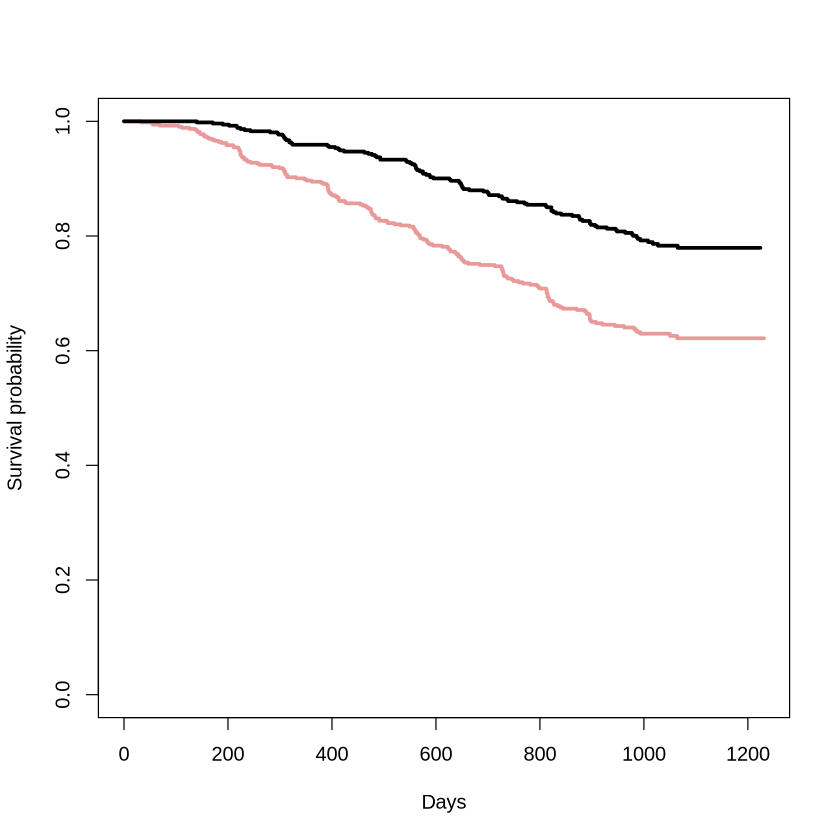

In [18]:
km_fit <- survfit(
  Surv(days, cens) ~ treat,
  data = df_test
)


plot(km_fit, col = c(red_theme, 'black'),
     xlab = "Days",
     ylab = "Survival probability",
     lwd = 3, )

In [19]:
fit <- coxph(
    Surv(days, cens) ~ treat * karnof + wtkg + gender + age + drugs,
    # Surv(days, cens) ~ treat * karnof + oprior,
    data <- df_test
)
summary(fit)

Call:
coxph(formula = Surv(days, cens) ~ treat * karnof + wtkg + gender + 
    age + drugs, data = data <- df_test)

  n= 1054, number of events= 284 

                  coef exp(coef)  se(coef)      z Pr(>|z|)  
treat         1.530022  4.618277  1.925080  0.795   0.4267  
karnof       -0.014000  0.986097  0.012192 -1.148   0.2508  
wtkg          0.006243  1.006263  0.004576  1.364   0.1725  
gender        0.310649  1.364310  0.182182  1.705   0.0882 .
age           0.004282  1.004292  0.006831  0.627   0.5307  
drugs        -0.378706  0.684747  0.213536 -1.774   0.0761 .
treat:karnof -0.023434  0.976839  0.020297 -1.155   0.2483  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

             exp(coef) exp(-coef) lower .95 upper .95
treat           4.6183     0.2165    0.1061   200.961
karnof          0.9861     1.0141    0.9628     1.010
wtkg            1.0063     0.9938    0.9973     1.015
gender          1.3643     0.7330    0.9546     1.950
age             1.0043

In [20]:
print(cox.zph(fit))

                chisq df     p
treat        5.76e+00  1 0.016
karnof       4.23e-02  1 0.837
wtkg         9.60e-03  1 0.922
gender       9.37e-01  1 0.333
age          2.07e-01  1 0.649
drugs        8.68e-05  1 0.993
treat:karnof 6.12e+00  1 0.013
GLOBAL       7.99e+00  7 0.334


In [21]:
broom::tidy(fit, exponentiate = TRUE, conf.int = TRUE)

term,estimate,std.error,statistic,p.value,conf.low,conf.high
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
treat,4.6182773,1.925080115,0.7947834,0.42673950,0.1061326,200.960716
karnof,0.9860975,0.012191927,-1.1483051,0.25084262,0.9628133,1.009945
wtkg,1.0062628,0.004576073,1.3643235,0.17246577,0.9972780,1.015328
gender,1.3643098,0.182182266,1.7051533,0.08816584,0.9546390,1.949786
age,1.0042916,0.006830688,0.6269438,0.53069609,0.9909359,1.017827
drugs,0.6847472,0.213535628,-1.7735005,0.07614580,0.4505764,1.040620
treat:karnof,0.9768386,0.020297352,-1.1545294,0.24828319,0.9387407,1.016483


In [22]:
output_cox <- broom::tidy(fit, exponentiate = TRUE, conf.int = TRUE) %>%
  mutate(
    across(c(estimate, conf.low, conf.high), ~ round(.x, 2)),
    `HR (95% CI)` = sprintf("%.2f (%.2f–%.2f)",
                            estimate, conf.low, conf.high)
  ) %>%
  mutate(p.value = format.pval(p.value, digits = 3, eps = 0.001)) %>%
  select(term, `HR (95% CI)`, p.value)

output_cox

term,HR (95% CI),p.value
<chr>,<chr>,<chr>
treat,4.62 (0.11–200.96),0.4267
karnof,0.99 (0.96–1.01),0.2508
wtkg,1.01 (1.00–1.02),0.1725
gender,1.36 (0.95–1.95),0.0882
age,1.00 (0.99–1.02),0.5307
drugs,0.68 (0.45–1.04),0.0761
treat:karnof,0.98 (0.94–1.02),0.2483


### Causal Forests
The above showed that `treat x karnof` wasn't significant
Being treated and tolerant to treatment didn't give you an additional boost to HR
So is there a high yield group that responded to treatment?

Causal forest helps here:

In [23]:
colnames(df_test)

[1] "pidnum"  "age"     "wtkg"    "hemo"    "homo"    "drugs"   "karnof" 
 [8] "oprior"  "z30"     "zprior"  "preanti" "race"    "gender"  "str2"   
[15] "strat"   "symptom" "treat"   "offtrt"  "cd40"    "cd420"   "cd496"  
[22] "r"       "cd80"    "cd820"   "cens"    "days"    "arms"

In [24]:
df_test <- prep_df(df )

No duplicate PIDNUMs found.



In [25]:
CAUSAL_COLS <- c('drugs', 'karnof', 'wtkg')
X <- df_test %>% select(any_of(CAUSAL_COLS)) #Covariates used in model 
Y <- df_test$days              #Outcome (numeric, null-free)
W <- df_test$treat #Treatment assignment
D <- df_test$cens #Event type: 0 = censored

In [ ]:
MAX_FUP <- max(df_test$days)
summary(df_test$days)

In [27]:
# causal_forest(
#   X,
#   Y,
#   W,
#   Y.hat = NULL,
#   W.hat = NULL,
#   num.trees = 2000,
#   # sample.weights = NULL,
#   # clusters = NULL,
#   # equalize.cluster.weights = FALSE,
#   # sample.fraction = 0.5,
#   # mtry = min(ceiling(sqrt(ncol(X)) + 20), ncol(X)),
#   # min.node.size = 5,
#   # honesty = TRUE,
#   # honesty.fraction = 0.5,
#   # honesty.prune.leaves = TRUE,
#   # alpha = 0.05,
#   # imbalance.penalty = 0,
#   # stabilize.splits = TRUE,
#   # ci.group.size = 2,
#   # tune.parameters = "none",
#   # tune.num.trees = 200,
#   # tune.num.reps = 50,
#   # tune.num.draws = 1000,
#   # compute.oob.predictions = TRUE,
#   # num.threads = NULL,
#   seed = 2020 #runif(1, 0, .Machine$integer.max)
# )

In [28]:
cf_fit <- causal_survival_forest(
  X,
  Y,
  W,
  D,
  # W.hat = NULL,
  # target = c("RMST", "survival.probability"),
  horizon = MAX_FUP,
  # failure.times = NULL,
  num.trees = 2000,
  # sample.weights = NULL,
  # clusters = NULL,
  # equalize.cluster.weights = FALSE,
  # sample.fraction = 0.5,
  # mtry = min(ceiling(sqrt(ncol(X)) + 20), ncol(X)),
  # min.node.size = 5,
  # honesty = TRUE,
  # honesty.fraction = 0.5,
  # honesty.prune.leaves = TRUE,
  # alpha = 0.05,
  # imbalance.penalty = 0,
  # stabilize.splits = TRUE,
  # ci.group.size = 2,
  # tune.parameters = "none",
  # compute.oob.predictions = TRUE,
  # fast.logrank = FALSE,
  # num.threads = NULL,
  seed = 2000 #runif(1, 0, .Machine$integer.max)
)



Warning message in causal_survival_forest(X, Y, W, D, horizon = MAX_FUP, num.trees = 2000, :
“Estimated censoring probabilities go as low as: 0.00072 - an identifying assumption is that there exists a fixed positive constant M such that the probability of observing an event past the maximum follow-up time  is at least M (i.e. P(T > horizon | X) > M). This warning appears when M is less than 0.05, at which point causal survival forest can not be expected to deliver reliable estimates.”


In [29]:
# Inspecting the predictions file:
str(predict(cf_fit))
# Since it only contains the predictions column, feeling safe to do :
df_test$cf_benefit <- as.numeric(predict(cf_fit)$predictions)
typeof(df_test$cf_benefit) #this gave 'double'

# instead going with:
df_test <- df_test %>%
  mutate(cf_benefit = as.numeric(
    predict(cf_fit)$predictions
  ))
typeof(df_test$cf_benefit) #this also gave 'double'


'data.frame':	1054 obs. of  1 variable:
 $ predictions: num  283.6 111.2 -182.4 219.6 50.4 ...


[1] "double"

[1] "double"

In [30]:
summary(df_test$cf_benefit)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
-1578.691  -133.542     3.463   -65.613   110.867   360.193 

In [31]:
df_test %>%
  summarise(
    across(
      all_of(CAUSAL_COLS),
      list(
        mean = ~ mean(.x, na.rm = TRUE),
        var  = ~ var(.x, na.rm = TRUE),
        sd   = ~ sd(.x, na.rm = TRUE)
      )
    )) %>%
  pivot_longer(
    everything(),
    names_to = c("variable", ".value"),
    names_sep = "_"
  )

variable,mean,var,sd
<chr>,<dbl>,<dbl>,<dbl>
drugs,0.1290323,0.1124897,0.3353948
karnof,95.4838710,34.4759979,5.8716265
wtkg,75.4718731,180.3498271,13.4294388


In [32]:
hi_yield <- df_test %>%
  filter(cf_benefit > 0)

hi_yield %>%
  summarise(
    across(
      all_of(CAUSAL_COLS),
      list(
        mean = ~ mean(.x, na.rm = TRUE),
        var  = ~ var(.x, na.rm = TRUE),
        sd   = ~ sd(.x, na.rm = TRUE)
      )
    )) %>%
  pivot_longer(
    everything(),
    names_to = c("variable", ".value"),
    names_sep = "_"
  )

variable,mean,var,sd
<chr>,<dbl>,<dbl>,<dbl>
drugs,0.1296992,0.1130899,0.3362885
karnof,98.7969925,12.4860173,3.5335559
wtkg,77.0933253,203.9154478,14.2798966


In [33]:
analysis_df <- df_test %>%
  mutate(
    benefit_group = if_else(
      cf_benefit > 0,
      "Positive benefit",
      "Zero/negative benefit"
    ) %>% factor(levels = c("Zero/negative benefit",
                            "Positive benefit"))
  )

analysis_df %>%
  count(benefit_group) %>%
  mutate(pct = n / sum(n) * 100)

benefit_group,n,pct
<fct>,<int>,<dbl>
Zero/negative benefit,522,49.52562
Positive benefit,532,50.47438


In [34]:
table(analysis_df$benefit_group, analysis_df$treat)

                       
                          0   1
  Zero/negative benefit 267 255
  Positive benefit      265 267

In [35]:
# library(ggplot2)

plot_benefit <- function(data, xvar, x_threshold) {
  ggplot(data, aes(x = .data[[xvar]], y = cf_benefit)) +
    geom_point(alpha = 0.35, size = 1.5) +
    geom_hline(yintercept = 0, linetype = "dashed",
               color = red_theme) +
    geom_vline(xintercept = x_threshold, linetype = "dashed",
               color = "steelblue") +
    labs(
      title = paste("Treatment benefit vs", xvar),
      x = xvar,
      y = "Predicted treatment benefit"
    ) +
    theme_minimal()
}

In [36]:
CAUSAL_COLS

[1] "drugs"  "karnof" "wtkg"

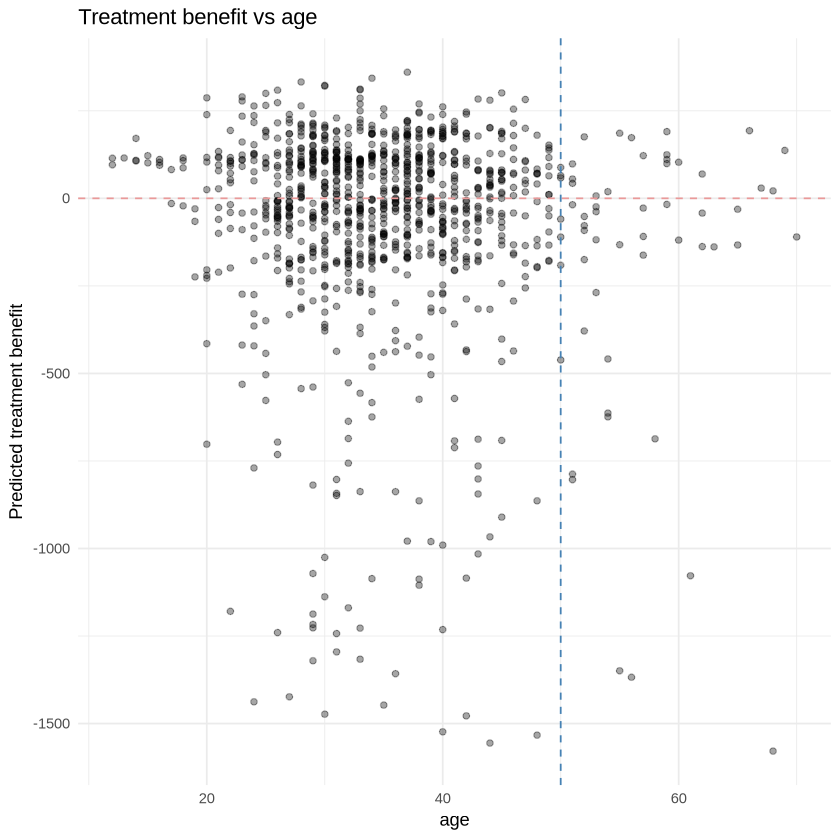

In [40]:
plot_benefit(df_test, xvar = 'age', x_threshold = 50)

In [38]:
vi <- variable_importance(cf_fit)

tibble(
  variable = colnames(X),
  importance = vi
) %>%
  arrange(desc(importance))

variable,importance
<chr>,"<dbl[,1]>"
wtkg,0.734326471
karnof,0.264300743
drugs,0.001372786


In [39]:
# train model on val sample, val_forest
rate <- rank_average_treatment_effect(
  val_forest,
  priorities = predicted_benefit
)

plot(rate)

rate$estimate
rate$std.err

ERROR: Error: object 'val_forest' not found


In [ ]:
# Metrics:
ate <- average_treatment_effect(cf_fit)
message("ATE:", ate)
blp <- best_linear_projection(
  cf_fit,
  A = X[, CAUSAL_COLS]
)

blp

ERROR: Error in library(gganimate): there is no package called ‘gganimate’


In [42]:

library(tidyverse)
library(grf)
library(gganimate)
library(gifski)

animate_benefit_horizons <- function(
    X, Y, W, D,
    horizons = c(168, 336, 504, 672),
    target = "RMST",
    num.trees = 2000,
    seed = 42,
    filename = "benefit_over_time.gif",
    fps = 12
) {

  forests <- map(horizons, \(h) {
    causal_survival_forest(
      X = X,
      Y = Y,
      W = W,
      D = D,
      target = target,
      horizon = h,
      num.trees = num.trees,
      seed = seed
    )
  })

  predictions <- map2_dfr(
    forests, horizons,
    \(forest, h) {
      tibble(
        patient_id = seq_len(nrow(X)),
        horizon = h,
        benefit = as.numeric(
          predict(forest)$predictions
        )
      )
    }
  )

  p <- ggplot(
    predictions,
    aes(x = benefit, fill = benefit > 0)
  ) +
    geom_histogram(
      bins = 45,
      alpha = 0.85
    ) +
    geom_vline(
      xintercept = 0,
      linetype = "dashed",
      linewidth = 0.8
    ) +
    scale_fill_manual(
      values = c(
        "TRUE" = "#C47A52",
        "FALSE" = "#7185A8"
      ),
      labels = c(
        "FALSE" = "Non-positive",
        "TRUE" = "Positive"
      )
    ) +
    labs(
      title = "Causal Benefit Across Time Horizons",
      subtitle = "RMST horizon: {closest_state} days",
      x = "Predicted treatment benefit (days)",
      y = "Number of patients",
      fill = "Predicted benefit"
    ) +
    theme_minimal(base_size = 14) +
    theme(
      plot.title = element_text(face = "bold"),
      legend.position = "bottom"
    ) +
    transition_states(
      horizon,
      transition_length = 2,
      state_length = 3
    ) +
    enter_fade() +
    exit_fade()

  animation <- animate(
    p,
    fps = fps,
    width = 1100,
    height = 750,
    renderer = gifski_renderer(loop = TRUE)
  )

  anim_save(filename, animation)

  invisible(list(
    forests = forests,
    predictions = predictions,
    plot = p,
    animation = animation
  ))
}


ERROR: Error in library(gganimate): there is no package called ‘gganimate’


In [ ]:
install.packages('gganimate')

also installing the dependencies ‘proxy’, ‘e1071’, ‘class’, ‘KernSmooth’, ‘wk’, ‘classInt’, ‘s2’, ‘units’, ‘sf’, ‘lpSolve’, ‘transformr’, ‘tweenr’




In [ ]:

library(ggplot2)
library(tidyr)
library(dplyr)

plot_benefit_heatmap <- function(
    forest,
    X,
    xvar,
    yvar,
    reference = list(),
    grid_size = 60,
    limits = c(0.02, 0.98)
) {

  X <- as.matrix(X)

  stopifnot(
    xvar %in% colnames(X),
    yvar %in% colnames(X),
    xvar != yvar
  )

  # Reference values for all other covariates
  ref <- map_dbl(seq_len(ncol(X)), \(j) {
    nm <- colnames(X)[j]

    if (nm %in% names(reference)) {
      return(reference[[nm]])
    }

    median(X[, j], na.rm = TRUE)
  })

  names(ref) <- colnames(X)

  # Restrict grid to observed covariate ranges
  x_seq <- seq(
    quantile(X[, xvar], limits[1], na.rm = TRUE),
    quantile(X[, xvar], limits[2], na.rm = TRUE),
    length.out = grid_size
  )

  y_seq <- seq(
    quantile(X[, yvar], limits[1], na.rm = TRUE),
    quantile(X[, yvar], limits[2], na.rm = TRUE),
    length.out = grid_size
  )

  grid <- expand_grid(
    !!xvar := x_seq,
    !!yvar := y_seq
  )

  # Construct prediction matrix
  newX <- matrix(
    rep(ref, each = nrow(grid)),
    nrow = nrow(grid)
  )

  colnames(newX) <- colnames(X)

  newX[, xvar] <- grid[[xvar]]
  newX[, yvar] <- grid[[yvar]]

  # Predict treatment effects
  grid$benefit <- as.numeric(
    predict(forest, newdata = newX)$predictions
  )

  # Plot
  p <- ggplot(
    grid,
    aes(
      x = .data[[xvar]],
      y = .data[[yvar]],
      fill = benefit
    )
  ) +
    geom_raster() +
    geom_contour(
      aes(z = benefit),
      breaks = 0,
      color = "white",
      linewidth = 0.9
    ) +
    scale_fill_gradient2(
      low = "#7185A8",
      mid = "#F0EEE9",
      high = "#C47A52",
      midpoint = 0,
      name = "Predicted\nbenefit"
    ) +
    labs(
      title = "Causal Treatment Benefit Landscape",
      subtitle = paste(xvar, "×", yvar),
      x = xvar,
      y = yvar
    ) +
    theme_minimal(base_size = 14) +
    theme(
      plot.title = element_text(face = "bold"),
      legend.position = "right"
    )

  invisible(list(
    predictions = grid,
    plot = p
  ))
}
